# Logistic Regression Baseline
Predict user churn (`is_churn = 1`) using `kkbox_v2_final2.csv`.

We use a stratified 80% training / 20% test split by user. With only one label period, this measures performance within the same period, not future-period generalization. Model settings and the 0.5 classification threshold are fixed in advance; the test set is not used for tuning. Add a validation set if tuning is needed later.


## 1. Imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             average_precision_score, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay)


## 2. Load and check the dataset

In [2]:
data_path = Path("kkbox_v2_final2.csv")
df = pd.read_csv(data_path)

# Each user must appear only once, so users cannot cross the split.
assert df["msno"].notna().all() and df["msno"].is_unique
assert df["is_churn"].notna().all() and df["is_churn"].isin([0, 1]).all()
print("Dataset shape:", df.shape)
display(df.head())
display(df["is_churn"].value_counts(normalize=True).rename("proportion"))


Dataset shape: (850295, 31)


                                           msno  is_churn  city   age  gender  registered_via    registration_date  has_listening_logs  active_days  total_songs  total_songs_100  total_unique_songs_daily  total_listening_secs  avg_secs_per_active_day     last_active_date  days_since_last_active  active_days_7d  active_days_30d  listening_secs_7d  listening_secs_30d  listening_secs_previous_30d  songs_30d  ever_cancel  cancel_count  cancel_ratio  last_is_cancel  days_since_last_cancel  cancel_count_30d  cancel_count_90d  transactions_since_last_cancel  noncancel_after_last_cancel
0  3SZforZjTfZwCqjrPMgF1Y21nwcmUea0KwmcEO2J9uA=         0   1.0  22.0  female             7.0  2016-07-29 00:00:00                   1          199       7706.0           4702.0                    6008.0           1326669.445              6666.680628  2017-02-28 00:00:00                       0               5               28          33107.345          163011.112                   218088.779      873.0       

0    0.905824
1    0.094176

## 3. Prepare features
Exclude the user ID and label. Convert registration date to tenure at the feature cutoff (2017-02-28); the existing `days_since_last_active` already represents listening recency. Treat city and registration channel as categories.

Missing numeric values are median-imputed with missingness indicators, so an absent cancellation date remains distinguishable. Preprocessing is fitted on training data only. All input aggregates must have been computed from information available by the cutoff.


In [3]:
X = df.drop(columns=["msno", "is_churn"]).copy()
y = df["is_churn"].astype(int)

cutoff = pd.Timestamp("2017-02-28")
registration = pd.to_datetime(X.pop("registration_date"), errors="coerce")
X["tenure_days"] = (cutoff - registration).dt.days
X.loc[X["tenure_days"] < 0, "tenure_days"] = np.nan
X = X.drop(columns=["last_active_date"])
X.loc[~X["age"].between(1, 100), "age"] = np.nan

categorical_cols = ["city", "gender", "registered_via"]
for col in categorical_cols:
    X[col] = X[col].fillna("Unknown").astype(str)
numeric_cols = X.columns.difference(categorical_cols).tolist()
X[numeric_cols] = X[numeric_cols].replace([np.inf, -np.inf], np.nan)


## 4. Split into training and test sets

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "churn_rate": [y_train.mean(), y_test.mean()]
}, index=["train", "test"])
display(split_summary)


         rows  churn_rate
train  680236    0.094176
test   170059    0.094173

## 5. Train Logistic Regression

In [5]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("logistic", LogisticRegression(max_iter=1000, random_state=42))
])
model.fit(X_train, y_train)
print("Training complete.")
print("Solver iterations:", model.named_steps["logistic"].n_iter_)


Training complete.
Solver iterations: [261]


## 6. Evaluate on the test set
Precision, recall and F1 use a fixed 0.5 threshold. PR-AUC is reported using average precision (AP), a common summary of the precision-recall curve, rather than trapezoidal integration. Its no-skill reference is the test churn rate.

Recall@10% is the fraction of all actual churners captured among the highest-risk 10% of test users (rounded up). Random ranking has an expected recall of approximately 10%.


In [6]:
y_prob = model.predict_proba(X_test)[:, 1]
y_pred = (y_prob >= 0.5).astype(int)

n_top = int(np.ceil(0.10 * len(y_test)))
top_indices = np.argsort(-y_prob, kind="stable")[:n_top]
recall_at_10 = y_test.iloc[top_indices].sum() / y_test.sum()

results = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1", "PR-AUC (Average Precision)", "Recall@10%"],
    "Score": [precision_score(y_test, y_pred, zero_division=0),
              recall_score(y_test, y_pred, zero_division=0),
              f1_score(y_test, y_pred, zero_division=0),
              average_precision_score(y_test, y_prob),
              recall_at_10]
})
display(results.round(4))
print(f"Test churn rate / no-skill AP: {y_test.mean():.4f}")
print(f"Top 10%: {n_top:,} users; captured churners: {y_test.iloc[top_indices].sum():,}")


Test churn rate / no-skill AP: 0.0942
Top 10%: 17,006 users; captured churners: 9,378


                       Metric   Score
0                   Precision  0.8074
1                      Recall  0.5168
2                          F1  0.6302
3  PR-AUC (Average Precision)  0.5810
4                  Recall@10%  0.5856

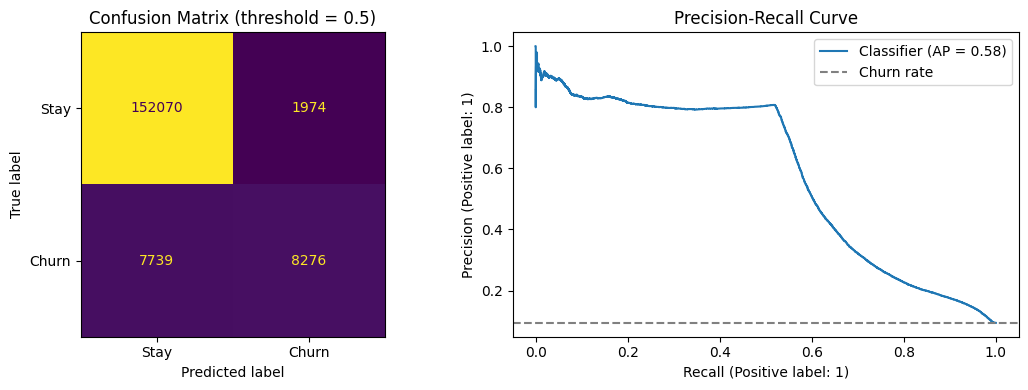

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["Stay", "Churn"], ax=axes[0], colorbar=False
)
axes[0].set_title("Confusion Matrix (threshold = 0.5)")
PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].axhline(y_test.mean(), linestyle="--", color="gray", label="Churn rate")
axes[1].set_title("Precision-Recall Curve")
axes[1].legend()
plt.tight_layout()
plt.show()


## 7. Interpretation and limitations
- Read recall and precision together: a 0.5 threshold may miss churners when churn is rare.
- Compare AP with the test churn rate and Recall@10% with the 10% random-ranking reference.
- The stratified random split does not establish performance on a later month.
- This dataset excludes the first 120,665 records from the original file; results describe the retained users and may be affected by the original row order.
- Do not tune features, model settings or the threshold on these test results. Use a separate validation split for that work.
